# 첫 실패 보기

**이 노트북에서 할 일**

1. 01~04절과 같은 E01 문서 청크로, 질문마다 답이 든 쪽의 출처를 묻기 전에 적어 둡니다.
2. E01에 답이 없는 와이파이 질문을 k=1로 보내고, 답과 검색 출처를 적어 둔 출처와 대조합니다.
3. 휴관일 질문을 k=1로 보낸 Before와 k=2로 보낸 After를 비교해, 답만으로는 안 보이는 검색 누락을 찾습니다.

**준비물** — 프로젝트 폴더 `.env` 파일의 `OPENAI_API_KEY`가 필요합니다. 데이터 파일은 `labs/data/rag-corpus/pdf/easy/E01.pdf`입니다.

인터넷 서비스에 요청을 모두 8번 보냅니다. 임베딩 모델 `text-embedding-3-small`에 5번, `gpt-5.4-mini`에 3번입니다.
실행 시간은 1분 안팎이고, 예상 비용은 0.01달러 미만으로 잡았습니다.
임베딩 요금은 OpenAI 모델 안내(2026-09-17 확인)에 적힌 100만 토큰당 0.02달러입니다.
mini 요금은 Ch 6 06절에서 확인한 값입니다.

**강의와 실습 범위** — 강의 시간에는 3·4절(정답 출처 적기, 답이 없는 질문)과 Before를 설명합니다.
5절 값 바꿔 보기와 After는 함께 실행하고 실습 시간에 읽습니다.

**기준 버전** — 실습 폴더에 고정한 패키지 판을 씁니다. pypdf 6.17.0, langchain 1.4.0, langchain-core 1.6.2입니다.
함께 쓰는 판은 langchain-openai 1.6.0, langchain-text-splitters 1.1.2입니다.
나머지는 openai 3.8.0과 python-dotenv 1.2.3입니다.

교재 출력은 Linux의 Python 3.12.13으로 만들었습니다. 다른 버전과 Windows·macOS에서는 이번에 실행하지 않았습니다.

실습 폴더 `labs/part3/ch09-rag-first-run`에서 `uv sync --locked`를 실행합니다.
그다음 이 폴더의 `.venv` 커널을 고르고 첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

![위 칸 와이파이 질문 k=1에는 초록 상자 정답 출처 빈 목록, 초록 상자 검색 출처 E01 p.1 표지, 노란 상자 빠진 정답 출처 없음 답이 없는 질문이 왼쪽에서 오른쪽으로 있고, 아래 칸 휴관일 질문 k=1 Before에는 초록 상자 정답 출처 E01 p.2, 초록 상자 검색 출처 E01 p.1 표지, 빨간 상자 빠진 정답 출처 E01 p.2 검색 누락이 차례로 있으며, 맨 아래 회색 상자에 두 질문 모두 k=1 검색 출처는 E01 p.1 답을 읽기 전에 정답 출처와 대조가 있는 비교 그림](attachment:05-1-검색-출처와-정답-출처.png)

위 칸은 4절 와이파이 질문, 아래 칸은 Before 휴관일 질문이고, 칸마다 왼쪽에서 오른쪽으로 읽습니다.
초록 상자는 묻기 전에 적은 정답 출처와 검색 출처입니다. 노란 상자는 출력으로 확인할 값, 빨간 상자는 Before의 결함 결과입니다.
두 칸의 검색 출처는 표지로 같습니다. 정답 출처가 달라서 끝 상자가 갈립니다.
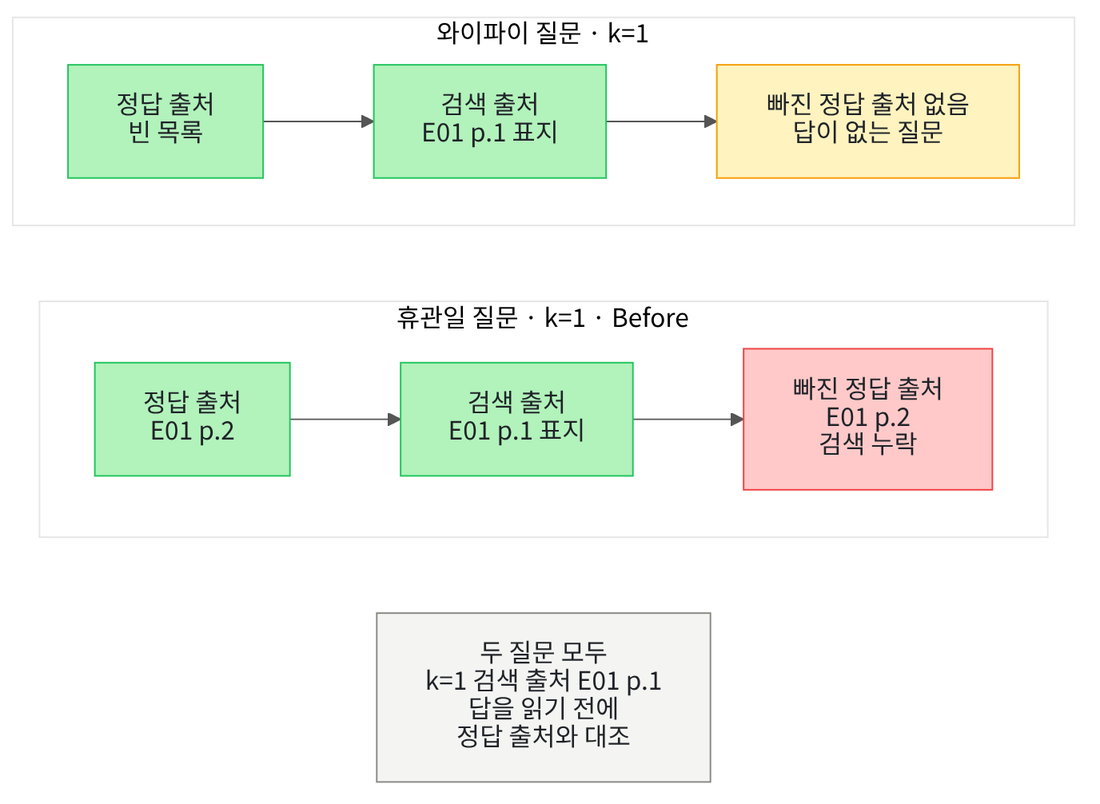

## 1. 준비

첫 셀은 패키지를 설치하고 설치된 버전을 출력합니다. 설치에는 몇십 초가 걸릴 수 있습니다.
04절과 같은 패키지를 씁니다. 이 노트북은 임베딩 모델과 답을 쓰는 모델을 모두 부릅니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "pypdf==6.17.0" "langchain==1.4.0" "langchain-openai==1.6.0" "langchain-text-splitters==1.1.2" "python-dotenv==1.2.3"
from importlib.metadata import version

print("pypdf:", version("pypdf"))
print("langchain:", version("langchain"))
print("langchain-core:", version("langchain-core"))
print("langchain-openai:", version("langchain-openai"))
print("langchain-text-splitters:", version("langchain-text-splitters"))
print("openai:", version("openai"))
print("python-dotenv:", version("python-dotenv"))

Note: you may need to restart the kernel to use updated packages.
pypdf: 6.17.0


langchain: 1.4.0
langchain-core: 1.6.2
langchain-openai: 1.6.0
langchain-text-splitters: 1.1.2
openai: 3.8.0
python-dotenv: 1.2.3


**결과 읽기** — 출력 줄은 `pypdf: 6.17.0`, `langchain: 1.4.0`, `openai: 3.8.0` 등 일곱 줄입니다.
준비물에 적은 기준 버전과 같습니다.

PDF 읽기, 문서 객체, 글 나누기, 임베딩, 벡터스토어, 모델 준비에 쓸 이름을 불러옵니다. 04절 준비 셀과 같은 이름입니다.

In [2]:
# PDF 읽기·문서 청크 나누기·임베딩·벡터스토어·모델 준비에 쓸 이름을 불러옵니다
import os

from pypdf import PdfReader
from langchain_core.documents import Document
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_openai import OpenAIEmbeddings
from langchain_core.vectorstores import InMemoryVectorStore
from langchain.chat_models import init_chat_model

01·04절과 같은 셀로 API 키가 있는지 확인합니다. 키 값은 출력하지 않고, 있는지만 봅니다.
`True` 값이 나오면 다음으로 넘어갑니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


01·04절과 같은 설정으로 답을 쓸 모델 객체를 만듭니다. 이 셀은 요청을 보내지 않습니다.
temperature 값을 0으로 두어 매번 비슷한 답을 고르게 합니다.

In [4]:
# 실습에 쓸 모델을 준비합니다
model = init_chat_model(
    "openai:gpt-5.4-mini",
    temperature=0,
    reasoning_effort="none",
)
print("모델 이름:", model.model_name)
print("temperature:", model.temperature)

모델 이름: gpt-5.4-mini
temperature: 0.0


**결과 읽기** — 모델 이름 `gpt-5.4-mini`, temperature `0.0`이 보이면 준비가 끝났습니다.
이 노트북의 출력은 2026-09-17에 이 모델로 실행한 결과입니다.
실행마다 답 문장이 달라질 수 있습니다. Ch 6 01절에서 본 것처럼 temperature 0은 Ch 5 06절의 뽑기를 끈 설정과 같은 것이 아닙니다.

## 2. 01~04절과 같은 문서 청크와 벡터스토어 만들기

이 노트북도 01~04절과 같은 E01 문서 청크 8개로 시작합니다. 경로를 고르는 셀은 04절과 같은 코드입니다.
실행 전에 예상합니다. 프로젝트 맨 위에서 열었다면 첫째 후보를 고를 것입니다.

In [5]:
# 작업 폴더에서 본 E01.pdf 경로를 후보 세 개 가운데에서 고릅니다
candidates = [
    "labs/data/rag-corpus/pdf/easy/E01.pdf",
    "../../data/rag-corpus/pdf/easy/E01.pdf",
    "../../../data/rag-corpus/pdf/easy/E01.pdf",
]
pdf_path = None
for candidate in candidates:
    if os.path.exists(candidate):
        pdf_path = candidate
        break
print("PDF를 찾았는가:", pdf_path is not None)
print("고른 경로:", pdf_path)
assert pdf_path is not None, "notebooks 폴더나 실습 폴더 맨 위에서 노트북을 열어 주세요."

PDF를 찾았는가: True
고른 경로: labs/data/rag-corpus/pdf/easy/E01.pdf


**결과 읽기** — 출력 줄은 `PDF를 찾았는가: True`와 `고른 경로: labs/data/rag-corpus/pdf/easy/E01.pdf`입니다.
교재 출력은 프로젝트 맨 위를 작업 폴더로 삼아 실행해서 첫째 후보를 골랐습니다.
`notebooks` 폴더에서 열면 셋째 후보가 나옵니다.

로더 함수 `load_pdf_pages()`는 02~04절과 같은 코드입니다. PDF 경로와 문서 이름을 받아, 쪽마다 Document를 담은 목록을 반환합니다.
메타데이터에는 문서 이름 `doc_id`, 쪽 번호 `page`, 파일 이름 `source` 세 키를 적습니다. 이 셀은 정의만 하므로 출력이 없습니다.

In [6]:
# PDF 경로와 문서 이름을 받아, 쪽마다 본문과 메타데이터를 담은 Document 목록을 반환하는 로더 함수를 정의합니다
def load_pdf_pages(pdf_path, doc_id):
    reader = PdfReader(pdf_path)
    page_documents = []
    page_number = 1
    for page in reader.pages:
        metadata = {"doc_id": doc_id, "page": page_number, "source": doc_id + ".pdf"}
        page_document = Document(page_content=page.extract_text(), metadata=metadata)
        page_documents.append(page_document)
        page_number = page_number + 1
    return page_documents

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다.

로더 함수로 다섯 쪽을 읽고, 01~04절과 같은 크기 500자·겹침 50자로 나눕니다.
그다음 03·04절처럼 빈 벡터스토어를 만들어 문서 청크를 넣습니다. 임베딩 객체 이름도 `embedding_model`로 같습니다.
실행 전에 예상합니다. 04절처럼 문서 청크 8개가 모두 저장될 것입니다.

In [7]:
# E01.pdf를 문서 청크로 나누고, 04절과 같은 방법으로 벡터스토어에 넣습니다(임베딩 요청 1번)
pages = load_pdf_pages(pdf_path, "E01")
splitter = RecursiveCharacterTextSplitter(chunk_size=500, chunk_overlap=50)
chunks = splitter.split_documents(pages)
embedding_model_name = "text-embedding-3-small"
embedding_model = OpenAIEmbeddings(model=embedding_model_name)
store = InMemoryVectorStore(embedding=embedding_model)
stored_ids = store.add_documents(chunks)
print("Document 수:", len(pages))
print("문서 청크 수:", len(chunks))
print("넣은 뒤 저장 항목 수:", len(store.store))

Document 수: 5
문서 청크 수: 8
넣은 뒤 저장 항목 수: 8


**결과 읽기** — 출력 줄은 `Document 수: 5`, `문서 청크 수: 8`, `넣은 뒤 저장 항목 수: 8`입니다. 01~04절과 같은 수입니다.

## 3. 묻기 전에 정답 출처 적어 두기

답이 「확인할 수 없습니다」로 오면, 답만 읽어서는 까닭을 가를 수 없습니다.
검색이 답이 든 문서 청크를 놓쳤을 수도 있고, E01에 답이 아예 없을 수도 있습니다.
그래서 질문을 보내기 전에, 질문마다 답이 든 쪽의 출처를 먼저 적어 둡니다.

이 출처를 이 절에서는 정답 출처라고 부릅니다. 시험 문제를 내기 전에 답이 있는 교과서 쪽을 적어 두는 것과 비슷합니다.
노트북에서는 `["E01 p.2"]`처럼 04절 기록의 출처 모양으로 적습니다.

먼저 문서 청크 8개를 모두 04절 기록 모양으로 옮겨, 쪽마다 어떤 출처가 붙는지 봅니다.
함수 `make_note()`는 04절과 같은 코드입니다. 이 셀은 정의만 하므로 출력이 없습니다.

In [8]:
# 문서 청크 하나를 받아, 문서 이름과 쪽 번호로 만든 출처와 본문을 담은 기록을 반환하는 함수를 정의합니다
def make_note(chunk):
    doc_id = chunk.metadata["doc_id"]
    page = chunk.metadata["page"]
    note = {"출처": f"{doc_id} p.{page}", "내용": chunk.page_content}
    return note

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다.

문서 청크 8개를 나눈 순서대로 기록으로 옮기고, 출처와 글자 수를 봅니다. 검색이 아니라서 요청을 보내지 않습니다.
실행 전에 예상합니다. 01절처럼 2쪽·3쪽·4쪽은 문서 청크가 둘씩이라, 같은 출처가 두 번씩 보일 것입니다.

In [9]:
# 문서 청크 8개를 모두 기록으로 옮기고, 기록마다 출처와 글자 수를 봅니다(요청 없음)
all_notes = []
for chunk in chunks:
    note = make_note(chunk)
    all_notes.append(note)
print("기록 수:", len(all_notes))
print("모든 기록(출처 | 글자 수):")
for note in all_notes:
    print(note["출처"], "|", len(note["내용"]))

기록 수: 8
모든 기록(출처 | 글자 수):
E01 p.1 | 45
E01 p.2 | 498
E01 p.2 | 452
E01 p.3 | 498
E01 p.3 | 462
E01 p.4 | 492
E01 p.4 | 412
E01 p.5 | 270


**결과 읽기** — 첫 줄은 `기록 수: 8`입니다. 라벨 줄 아래 여덟 줄은 `E01 p.1 | 45`로 시작합니다.
그다음 `E01 p.2 | 498`과 `E01 p.2 | 452`가 이어지고, 마지막 줄은 `E01 p.5 | 270`입니다.

출처는 쪽 번호까지만 적으므로, 한 쪽에서 나온 두 문서 청크는 출처가 같습니다.
그래서 이 절의 정답 출처도 쪽 단위로 적습니다.

함수 `find_missing_words()`는 Ch 8 03절과 이 챕터 02~04절에서 쓴 코드와 같습니다. 글에 들어 있지 않은 말만 모아 반환합니다.
이 셀은 정의만 하므로 출력이 없습니다.

In [10]:
# 글에 들어 있지 않은 지킬 말만 모아 반환하는 함수를 정의합니다(Ch 8 03절과 같은 코드)
def find_missing_words(text, words):
    missing = []
    for word in words:
        if word not in text:
            missing.append(word)
    return missing

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다.

첫 질문은 01절 휴관일 질문과 같은 글입니다. 이름은 Ch 8에서 쓴 `closure_question`으로 둡니다.
지킬 말도 Ch 8 03절과 이 챕터 02절의 `closure_keep_words`와 같은 세 말입니다.
기록마다 빠진 지킬 말을 보면, 사람이 원문에서 읽은 휴관 문장이 어느 기록에 있는지 코드로 한 번 더 확인할 수 있습니다.

실행 전에 예상합니다. 세 말이 모두 든 기록은 2쪽의 498자 기록 하나일 것입니다.

In [11]:
# 01절 휴관일 질문과 Ch 8 03절 지킬 말로, 기록마다 빠진 지킬 말을 봅니다(요청 없음)
closure_question = "미르시립도서관의 정기 휴관일은 언제이고, 공휴일이 월요일과 겹치면 어떻게 되나요?"
closure_keep_words = ["월요일", "법정 공휴일", "화요일"]
print("휴관일 질문의 지킬 말이 빠진 기록(출처 | 글자 수 | 빠진 지킬 말):")
for note in all_notes:
    missing = find_missing_words(note["내용"], closure_keep_words)
    print(note["출처"], "|", len(note["내용"]), "|", missing)

휴관일 질문의 지킬 말이 빠진 기록(출처 | 글자 수 | 빠진 지킬 말):
E01 p.1 | 45 | ['월요일', '법정 공휴일', '화요일']
E01 p.2 | 498 | []
E01 p.2 | 452 | ['월요일', '법정 공휴일', '화요일']
E01 p.3 | 498 | ['월요일', '법정 공휴일', '화요일']
E01 p.3 | 462 | ['월요일', '법정 공휴일', '화요일']
E01 p.4 | 492 | ['월요일', '법정 공휴일', '화요일']
E01 p.4 | 412 | ['월요일', '법정 공휴일', '화요일']
E01 p.5 | 270 | ['월요일', '법정 공휴일', '화요일']


**결과 읽기** — 라벨 줄 아래 여덟 줄 가운데 빈 목록은 `E01 p.2 | 498 | []` 한 줄뿐입니다.
나머지 일곱 줄은 `['월요일', '법정 공휴일', '화요일']`로, 세 말이 모두 빠졌습니다.
같은 2쪽이라도 `E01 p.2 | 452` 기록에는 세 말이 없습니다.

둘째 질문은 와이파이 비밀번호를 묻습니다. E01 다섯 쪽을 읽어 보면 와이파이 이야기가 없습니다.
그래서 이 질문을 E01에 답이 없는 질문의 예로 씁니다.

코드로도 한 번 더 확인합니다. 와이파이는 「Wi-Fi」「무선」「인터넷」으로 적을 수도 있어 네 말을 함께 찾습니다.
실행 전에 예상합니다. 모든 기록에서 네 말이 모두 빠져, 빠진 말 수가 4일 것입니다.

In [12]:
# E01에 답이 없는 와이파이 질문과, 답에 나올 만한 말로 기록마다 빠진 말 수를 봅니다(요청 없음)
wifi_question = "미르시립도서관의 와이파이 비밀번호는 무엇인가요?"
wifi_words = ["와이파이", "Wi-Fi", "무선", "인터넷"]
print("와이파이 말이 빠진 기록(출처 | 빠진 말 수):")
for note in all_notes:
    missing = find_missing_words(note["내용"], wifi_words)
    print(note["출처"], "|", len(missing))

와이파이 말이 빠진 기록(출처 | 빠진 말 수):
E01 p.1 | 4
E01 p.2 | 4
E01 p.2 | 4
E01 p.3 | 4
E01 p.3 | 4
E01 p.4 | 4
E01 p.4 | 4
E01 p.5 | 4


**결과 읽기** — 라벨 줄 아래 여덟 줄이 `E01 p.1 | 4`부터 `E01 p.5 | 4`까지 모두 4입니다.
어느 기록에도 네 말이 하나도 없습니다.

이 표는 말이 있는지만 봅니다. 네 말과 다른 표기로 적힌 글은 찾지 못하므로, 원문을 읽은 판단이 먼저입니다.

두 표를 보고 질문마다 정답 출처를 적습니다. 휴관일 질문은 2쪽, 와이파이 질문은 빈 목록입니다.
이 목록은 질문을 보내기 전에 사람이 정한 값이라, 모델 답과 상관없이 실행할 때마다 같습니다.

In [13]:
# 원문을 읽고 위 두 표로 확인한 정답 출처를 질문마다 적어 둡니다
closure_answer_sources = ["E01 p.2"]
wifi_answer_sources = []
print("휴관일 질문의 정답 출처:", closure_answer_sources)
print("와이파이 질문의 정답 출처:", wifi_answer_sources)

휴관일 질문의 정답 출처: ['E01 p.2']
와이파이 질문의 정답 출처: []


**결과 읽기** — 출력 줄은 `휴관일 질문의 정답 출처: ['E01 p.2']`와 `와이파이 질문의 정답 출처: []`입니다.

정답 출처가 빈 목록인 질문을 이 절에서는 답이 없는 질문이라고 부릅니다. 색인한 자료 어디에도 답이 없는 질문입니다.
안내 책자에 없는 것을 묻는 손님의 질문과 비슷합니다.

## 4. 답이 없는 질문을 k=1로 보내기

메시지 목록은 01·04절과 같은 모양입니다. system에는 페르소나, developer에는 과업 명세, user에는 근거와 질문을 넣습니다.
과업 명세는 04절 글 뒤에 Ch 5 07절 보류 지시를 한 문장 더했습니다. 근거에 답이 없으면 정해 둔 보류 문장으로 답하게 합니다.
보류 문장은 Ch 5 07절과 같은 「제공된 정보로는 확인할 수 없습니다」이고, 이름도 같은 `abstain_sentence`로 둡니다.

In [14]:
# 04절 글에 Ch 5 07절 보류 지시를 한 문장 더한 과업 명세와 보류 문장을 만듭니다
persona_text = "당신은 미르시립도서관 안내 담당자입니다."
task_text = "주어진 근거에 있는 정보만 쓰세요. 두 문장 이내로 답하고, 문장마다 끝에 근거 앞에 붙은 출처 표시를 그대로 적으세요."
task_text = task_text + " 근거에 답이 없으면 추측하지 말고 '제공된 정보로는 확인할 수 없습니다'라고 답하세요."
abstain_sentence = "제공된 정보로는 확인할 수 없습니다"
print("페르소나:", persona_text)
print("과업 명세:", task_text)
print("보류 문장:", abstain_sentence)

페르소나: 당신은 미르시립도서관 안내 담당자입니다.
과업 명세: 주어진 근거에 있는 정보만 쓰세요. 두 문장 이내로 답하고, 문장마다 끝에 근거 앞에 붙은 출처 표시를 그대로 적으세요. 근거에 답이 없으면 추측하지 말고 '제공된 정보로는 확인할 수 없습니다'라고 답하세요.
보류 문장: 제공된 정보로는 확인할 수 없습니다


**결과 읽기** — 세 줄은 `페르소나:`, `과업 명세:`, `보류 문장:`으로 시작합니다.
과업 명세 줄은 04절 글 뒤에 `근거에 답이 없으면 추측하지 말고`로 시작하는 문장이 이어집니다.

함수 `build_notes_messages()`는 Ch 8 04절·이 챕터 04절과 같은 코드입니다. 기록마다 대괄호 출처 표시와 내용을 이어 user 글을 만듭니다.
함수 안에서 바깥 이름 `persona_text`와 `task_text`를 읽습니다. 이 셀은 정의만 하므로 출력이 없습니다.

In [15]:
# 기록 목록과 질문 하나로 Ch 7 모양의 메시지 목록을 만들어 반환하는 함수를 정의합니다(Ch 8 04절과 같은 코드)
def build_notes_messages(notes, question):
    evidence_text = ""
    for note in notes:
        evidence_text = evidence_text + "[" + note["출처"] + "] " + note["내용"] + "\n"
    user_text = evidence_text + "\n" + "질문: " + question
    messages = [
        ("system", persona_text),
        ("developer", task_text),
        ("user", user_text),
    ]
    return messages

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다.

와이파이 질문을 k=1로 검색해, 04절처럼 검색 결과를 기록으로 옮깁니다. 기록의 출처만 따로 모은 목록이 검색 출처입니다.
k=1은 01절 6절에서 휴관일 질문으로 한 번 쓴 값입니다. 그때는 표지 한 개만 나왔습니다.

실행 전에 예상합니다. 와이파이 기록이 없으니, 어떤 문서 청크가 나와도 답이 든 근거는 아닐 것입니다.

In [16]:
# 와이파이 질문을 k=1로 검색해 기록으로 옮기고, 검색 출처를 봅니다(임베딩 요청 1번)
wifi_hits = store.similarity_search(wifi_question, k=1)
wifi_notes = []
wifi_sources = []
for hit in wifi_hits:
    note = make_note(hit)
    wifi_notes.append(note)
    wifi_sources.append(note["출처"])
print("k=1 검색 결과(출처 | 글자 수 | 앞 20자):")
for note in wifi_notes:
    print(note["출처"], "|", len(note["내용"]), "|", note["내용"][:20].replace("\n", " "))
print("검색 출처:", wifi_sources)

k=1 검색 결과(출처 | 글자 수 | 앞 20자):
E01 p.1 | 45 | 미르시립도서관 이용 안내 미르시립도서
검색 출처: ['E01 p.1']


**결과 읽기** — 라벨 줄 아래 한 줄은 `E01 p.1 | 45 | 미르시립도서관 이용 안내 미르시립도서`입니다.
마지막 줄은 `검색 출처: ['E01 p.1']`입니다.

와이파이 질문에서도 01절 휴관일 질문처럼 표지가 가장 가까웠습니다. 표지 45자에는 도서관 이름과 발행 정보만 있습니다.

이 목록을 모델로 보냅니다. 답은 여러 줄일 수 있어 라벨 줄 `답:`을 따로 출력합니다.
끝 줄에서는 답에 보류 문장이 들어 있는지 `in`으로 봅니다.
실행 전에 예상합니다. 근거에 와이파이 이야기가 없으니, 보류 문장으로 답할 것입니다.

In [17]:
# 와이파이 질문 목록을 모델로 보내고, 답과 보류 문장이 있는지 봅니다(요청 1번)
wifi_messages = build_notes_messages(wifi_notes, wifi_question)
wifi_response = model.invoke(wifi_messages)
wifi_text = wifi_response.text
print("답:")
print(wifi_text)
print("보류 문장 있음:", abstain_sentence in wifi_text)

답:
제공된 정보로는 확인할 수 없습니다. [E01 p.1]
보류 문장 있음: True


**결과 읽기** — 라벨 줄 아래 답은 `제공된 정보로는 확인할 수 없습니다. [E01 p.1]`입니다.
마지막 줄은 `보류 문장 있음: True`입니다.

이번 실행에서 모델은 과업 명세의 보류 문장으로 답했습니다. 그런데 보류 문장 뒤에도 표지 출처 표시 `[E01 p.1]`을 붙였습니다.
표지에는 와이파이 이야기가 없어서, 이 표시가 가리키는 기록은 답의 내용을 뒷받침하지 않습니다.

함수 `find_missing_sources()`는 정답 출처 가운데 검색 출처 목록에 없는 것만 모아 반환합니다.
모양은 `find_missing_words()`와 같고, 글 대신 검색 출처 목록에서 찾는 점만 다릅니다. 이 셀은 정의만 하므로 출력이 없습니다.

In [18]:
# 정답 출처 가운데 검색 출처 목록에 없는 것만 모아 반환하는 함수를 정의합니다
def find_missing_sources(hit_sources, answer_sources):
    missing = []
    for source in answer_sources:
        if source not in hit_sources:
            missing.append(source)
    return missing

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다.

함수 `find_cited_notes()`는 Ch 8 02절·이 챕터 04절과 같은 코드입니다. 답 글에 출처 표시가 들어 있는 기록만 모읍니다.
이 셀도 정의만 합니다.

In [19]:
# 답 글에 출처 표시가 들어 있는 기록만 골라 반환하는 함수를 정의합니다(Ch 8 02절과 같은 코드)
def find_cited_notes(answer_text, notes):
    cited = []
    for note in notes:
        mark = "[" + note["출처"] + "]"
        if mark in answer_text:
            cited.append(note)
    return cited

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다.

함수 `find_new_words()`는 답에는 있지만 입력 글에는 없는 말만 모아 반환합니다.
Ch 5 07절 `find_new_numbers()`가 질문과 문서에 없던 숫자를 찾은 것과 같은 생각입니다. 이번에는 숫자 대신 3절에서 정한 말 목록으로 찾습니다.

입력 글로는 근거와 질문이 함께 든 user 글 `wifi_messages[2][1]`을 넣습니다. 04절에서 user 글을 꺼낸 모양과 같습니다.
이 셀도 정의만 합니다.

In [20]:
# 답에는 있지만 입력 글에는 없는 말만 모아 반환하는 함수를 정의합니다(Ch 5 07절 find_new_numbers와 같은 생각)
def find_new_words(answer_text, source_text, words):
    new_words = []
    for word in words:
        if word in answer_text and word not in source_text:
            new_words.append(word)
    return new_words

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다.

와이파이 답에서 세 가지를 봅니다. 답의 출처 표시와 같은 기록 수, 검색 결과에 없는 정답 출처, user 글에 없는데 답에 나온 말입니다.
실행 전에 예상합니다. 정답 출처가 빈 목록이라, 검색 결과에 없는 정답 출처도 빈 목록일 것입니다.

In [21]:
# 와이파이 답을 검사해, 검색 결과에 없는 정답 출처와 user 글에 없는데 답에 나온 말을 봅니다
wifi_cited = find_cited_notes(wifi_text, wifi_notes)
wifi_missing_sources = find_missing_sources(wifi_sources, wifi_answer_sources)
wifi_new_words = find_new_words(wifi_text, wifi_messages[2][1], wifi_words)
print("답의 출처 표시와 같은 기록 수:", len(wifi_cited))
print("검색 결과에 없는 정답 출처:", wifi_missing_sources)
print("user 글에 없는데 답에 나온 말:", wifi_new_words)

답의 출처 표시와 같은 기록 수: 1
검색 결과에 없는 정답 출처: []
user 글에 없는데 답에 나온 말: []


**결과 읽기** — 출력 줄은 `답의 출처 표시와 같은 기록 수: 1`과 `검색 결과에 없는 정답 출처: []`입니다.
마지막 줄은 `user 글에 없는데 답에 나온 말: []`입니다.

답의 표시가 넣은 표지 기록과 같아서 1개가 맞았습니다. 04절에서 본 것처럼 이 검사는 표시가 답에 있는지만 봅니다.
검색 결과에 없는 정답 출처가 빈 목록인 것은, 정답 출처가 처음부터 빈 목록이기 때문입니다. 검색이 무엇을 놓친 것이 아닙니다.
이번 답은 와이파이 네 말을 쓰지 않아, user 글에 없던 말도 없었습니다.

정리하면 와이파이 질문은 답이 없는 질문이고, 이번 실행에서 모델은 보류로 답했습니다.

## 5. 값 바꿔 보기 — 와이파이 질문의 k를 1에서 8로

바꾸는 값은 검색 개수 k 하나입니다. 문서 청크가 8개뿐이라, k=8이면 모든 문서 청크가 검색 결과에 들어옵니다.
이번에는 검색만 하고 모델에는 보내지 않습니다. 검색 결과마다 3절의 와이파이 네 말이 하나라도 있는지 셉니다.

실행 전에 예상합니다. 검색 결과는 8개이고, 와이파이 말이 든 결과는 0개일 것입니다.

In [22]:
# 와이파이 질문을 k=8로 검색해, 네 말 가운데 하나라도 든 검색 결과 수를 셉니다(임베딩 요청 1번)
wide_hits = store.similarity_search(wifi_question, k=8)
word_hit_count = 0
for hit in wide_hits:
    missing = find_missing_words(hit.page_content, wifi_words)
    if len(missing) < len(wifi_words):
        word_hit_count = word_hit_count + 1
print("k=8 검색 결과 수:", len(wide_hits))
print("와이파이 말이 하나라도 든 검색 결과 수:", word_hit_count)

k=8 검색 결과 수: 8
와이파이 말이 하나라도 든 검색 결과 수: 0


**결과 읽기** — 출력 줄은 `k=8 검색 결과 수: 8`과 `와이파이 말이 하나라도 든 검색 결과 수: 0`입니다.

검색 개수 k를 문서 청크 수만큼 늘려도 와이파이 말이 든 근거는 들어오지 않았습니다. 색인한 E01에 없는 내용은 검색 개수를 늘려도 생기지 않습니다.
그래서 이 질문은 k를 바꿔 다시 보내지 않았습니다. 이 결과는 3절 표와 같은 뜻을 검색으로 한 번 더 확인한 것입니다.

## Before — 휴관일 질문을 k=1로 보내기

이번에는 E01에 답이 있는 휴관일 질문입니다. 정답 출처는 3절에서 적은 `['E01 p.2']`입니다.
실패 조건 Before는 4절 와이파이 질문과 같은 k=1로 검색해 목록을 만듭니다. 페르소나, 과업 명세, 모델도 4절과 같고, 질문만 다릅니다.

실행 전에 예상합니다. 01절 6절처럼 표지 한 개만 나와, 정답 출처 2쪽이 검색 결과에서 빠질 것입니다.

In [23]:
# 휴관일 질문을 k=1로 검색해 기록으로 옮기고, 검색 출처를 봅니다(임베딩 요청 1번)
before_hits = store.similarity_search(closure_question, k=1)
before_notes = []
before_sources = []
for hit in before_hits:
    note = make_note(hit)
    before_notes.append(note)
    before_sources.append(note["출처"])
print("k=1 검색 결과(출처 | 글자 수 | 앞 20자):")
for note in before_notes:
    print(note["출처"], "|", len(note["내용"]), "|", note["내용"][:20].replace("\n", " "))
print("검색 출처:", before_sources)

k=1 검색 결과(출처 | 글자 수 | 앞 20자):
E01 p.1 | 45 | 미르시립도서관 이용 안내 미르시립도서
검색 출처: ['E01 p.1']


**결과 읽기** — 라벨 줄 아래 한 줄은 `E01 p.1 | 45 | 미르시립도서관 이용 안내 미르시립도서`입니다.
마지막 줄은 `검색 출처: ['E01 p.1']`입니다.

01절 6절과 같은 표지 한 개이고, 4절 와이파이 질문의 검색 출처와도 같습니다.
정답 출처 `E01 p.2`는 검색 결과에 없습니다. 이 목록에는 휴관 문장이 든 근거가 하나도 들어가지 않습니다.

이 목록을 4절과 같은 모델로 보냅니다. 실행 전에 예상합니다. 근거에 휴관 이야기가 없으니, 4절처럼 보류 문장으로 답할 것입니다.

In [24]:
# 휴관일 질문 목록을 같은 모델로 보내고, 답과 보류 문장이 있는지 봅니다(요청 1번)
before_messages = build_notes_messages(before_notes, closure_question)
before_response = model.invoke(before_messages)
before_text = before_response.text
print("답:")
print(before_text)
print("보류 문장 있음:", abstain_sentence in before_text)

답:
미르시립도서관의 정기 휴관일은 매주 월요일입니다. 공휴일이 월요일과 겹치면 휴관일은 다음 날로 변경됩니다. [E01 p.1]
보류 문장 있음: False


**결과 읽기** — 라벨 줄 아래 답은 `미르시립도서관의 정기 휴관일은 매주 월요일입니다.`로 시작합니다.
둘째 문장은 `공휴일이 월요일과 겹치면 휴관일은 다음 날로 변경됩니다.`이고, 끝에 `[E01 p.1]`이 붙었습니다.
마지막 줄은 `보류 문장 있음: False`입니다.

이번 실행에서는 보류 문장이 아니라 휴관 내용을 적은 답이 왔습니다. 목록의 근거는 표지 45자뿐이라, 이 내용을 뒷받침하는 글이 입력에 없습니다.
모델이 이 내용을 어디에서 가져왔는지는 이 실행으로 알 수 없습니다.

01절 2절에서 출력한 E01 2쪽 원문과 대조합니다. 「매주 월요일」은 원문과 같습니다.
원문은 법정 공휴일에도 휴관하고, 공휴일이 월요일과 겹치면 그 다음 날인 화요일에도 휴관한다고 했습니다.
답의 「휴관일은 다음 날로 변경」은 휴관일이 옮겨진다는 뜻으로 읽혀, 원문과 다릅니다.
입력에도 원문에도 뒷받침이 없는 이 문장은 Ch 5 07절 뜻의 환각입니다.

함수 `check_answer()`는 Ch 8 04절 코드와 같습니다. 바깥 지킬 말 이름도 Ch 8과 같은 `closure_keep_words`입니다.
답의 출처 표시와 같은 기록, 답에서 빠진 지킬 말을 딕셔너리로 반환합니다. 이 셀은 정의만 하므로 출력이 없습니다.

In [25]:
# 답 글과 넣은 기록 목록으로, 답의 출처 표시와 같은 기록과 답에서 빠진 지킬 말을 모아 반환하는 함수를 정의합니다
def check_answer(answer_text, notes):
    cited = find_cited_notes(answer_text, notes)
    cited_sources = []
    for note in cited:
        cited_sources.append(note["출처"])
    missing = find_missing_words(answer_text, closure_keep_words)
    check = {"답의 출처 표시와 같은 기록": cited_sources, "답에서 빠진 지킬 말": missing}
    return check

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다.

Before 답을 검사하고, 검색 결과에 없는 정답 출처를 봅니다.
실행 전에 예상합니다. 검색 결과에 없는 정답 출처가 `['E01 p.2']`로 나올 것입니다.

In [26]:
# Before 답을 검사하고, 검색 결과에 없는 정답 출처와 user 글에 없는데 답에 나온 지킬 말을 봅니다
before_check = check_answer(before_text, before_notes)
before_missing_sources = find_missing_sources(before_sources, closure_answer_sources)
before_new_words = find_new_words(before_text, before_messages[2][1], closure_keep_words)
print("답 검사:", before_check)
print("검색 결과에 없는 정답 출처:", before_missing_sources)
print("user 글에 없는데 답에 나온 말:", before_new_words)

답 검사: {'답의 출처 표시와 같은 기록': ['E01 p.1'], '답에서 빠진 지킬 말': ['법정 공휴일', '화요일']}
검색 결과에 없는 정답 출처: ['E01 p.2']
user 글에 없는데 답에 나온 말: []


**결과 읽기** — 첫 줄은 `답 검사: {'답의 출처 표시와 같은 기록': ['E01 p.1'], '답에서 빠진 지킬 말': ['법정 공휴일', '화요일']}`입니다.
둘째 줄은 `검색 결과에 없는 정답 출처: ['E01 p.2']`입니다. 마지막 줄은 `user 글에 없는데 답에 나온 말: []`입니다.

답 검사는 표지 기록이 답의 표시와 같다고 했습니다. 표지에는 휴관 이야기가 없는데도 맞았으니, 표시 검사로는 근거 없는 답이 보이지 않습니다.
빠진 지킬 말은 답에 무엇이 없는지만 알려 줍니다. 검색이 놓친 것인지, 답을 쓰며 빠뜨린 것인지는 알려 주지 않습니다.

「월요일」은 질문에도 있는 말이라 `find_new_words()`가 새 말로 세지 않았습니다.
Ch 5 07절에서 질문에 있던 숫자를 새 숫자로 세지 않은 것과 같은 한계입니다.

까닭을 보여 준 것은 둘째 줄입니다. 정답 출처가 벡터스토어에는 있는데 검색 결과에 들지 않은 경우를, 이 절에서는 검색 누락이라고 부릅니다.
답이 적힌 쪽이 책에 있는데 다른 쪽만 펴 본 것과 비슷합니다. 실패 조건 Before의 결함은 답 검사 줄이 아니라 이 줄에서 보입니다.

## After — 휴관일 질문을 k=2로 다시 보내기

고치는 값은 검색 개수 k 하나입니다. 01절 5절에서 휴관일 질문으로 쓴 k=2로 검색합니다.
질문, 페르소나, 과업 명세, 모델은 Before와 같습니다.

실행 전에 예상합니다. 01절처럼 표지와 2쪽 문서 청크가 나와, 정답 출처가 검색 결과에 들어올 것입니다.

In [27]:
# 휴관일 질문을 k=2로 검색해 기록으로 옮기고, 검색 출처를 봅니다(임베딩 요청 1번)
after_hits = store.similarity_search(closure_question, k=2)
after_notes = []
after_sources = []
for hit in after_hits:
    note = make_note(hit)
    after_notes.append(note)
    after_sources.append(note["출처"])
print("k=2 검색 결과(출처 | 글자 수 | 앞 20자):")
for note in after_notes:
    print(note["출처"], "|", len(note["내용"]), "|", note["내용"][:20].replace("\n", " "))
print("검색 출처:", after_sources)

k=2 검색 결과(출처 | 글자 수 | 앞 20자):
E01 p.1 | 45 | 미르시립도서관 이용 안내 미르시립도서
E01 p.2 | 498 | 1. 도서관 소개 미르시립도서관은 1
검색 출처: ['E01 p.1', 'E01 p.2']


**결과 읽기** — 라벨 줄 아래 두 줄은 `E01 p.1 | 45 | 미르시립도서관 이용 안내 미르시립도서`와 `E01 p.2 | 498 | 1. 도서관 소개 미르시립도서관은 1`입니다.
마지막 줄은 `검색 출처: ['E01 p.1', 'E01 p.2']`입니다.

01절 5절과 같은 순서입니다. 둘째 자리에 3절 표에서 휴관 지킬 말이 모두 든 2쪽 498자 기록이 들어왔습니다.

표지는 그대로 첫째 자리에 남았습니다. 휴관일 질문에 필요 없는 내용이 목록에 함께 들어간 것입니다.
Ch 8 04절 이름으로는 혼란 조건입니다. 조건을 넣은 것과 답이 나빠졌는지는 답을 보고 따로 적습니다.

이 목록을 Before와 같은 모델로 보냅니다. 실행 전에 예상합니다. 01절 8절 답처럼 휴관 문장 끝에 2쪽 출처 표시가 붙을 것입니다.

In [28]:
# k=2 목록을 같은 모델로 보내고, 답과 보류 문장이 있는지 봅니다(요청 1번)
after_messages = build_notes_messages(after_notes, closure_question)
after_response = model.invoke(after_messages)
after_text = after_response.text
print("답:")
print(after_text)
print("보류 문장 있음:", abstain_sentence in after_text)

답:
미르시립도서관의 정기 휴관일은 매주 월요일입니다. 공휴일이 월요일과 겹치면 그 다음 날인 화요일에도 휴관합니다. [E01 p.2]
보류 문장 있음: False


**결과 읽기** — 라벨 줄 아래 답은 `미르시립도서관의 정기 휴관일은 매주 월요일입니다.`로 시작합니다.
둘째 문장은 `공휴일이 월요일과 겹치면 그 다음 날인 화요일에도 휴관합니다.`이고, 끝에 `[E01 p.2]`가 붙었습니다.
마지막 줄은 `보류 문장 있음: False`입니다.

이번 답의 휴관 내용은 목록에 넣은 2쪽 기록에 있습니다. 출처 표시도 2쪽 기록을 가리켰고, 표지 표시는 답에 없습니다.
혼란 조건을 넣었지만, 이번 답에서는 표지 내용을 쓴 곳을 찾지 못했습니다.

After 답을 Before와 같은 세 가지로 검사합니다. 실행 전에 예상합니다. 검색 결과에 없는 정답 출처가 빈 목록일 것입니다.

In [29]:
# After 답을 검사하고, 검색 결과에 없는 정답 출처와 user 글에 없는데 답에 나온 지킬 말을 봅니다
after_check = check_answer(after_text, after_notes)
after_missing_sources = find_missing_sources(after_sources, closure_answer_sources)
after_new_words = find_new_words(after_text, after_messages[2][1], closure_keep_words)
print("답 검사:", after_check)
print("검색 결과에 없는 정답 출처:", after_missing_sources)
print("user 글에 없는데 답에 나온 말:", after_new_words)

답 검사: {'답의 출처 표시와 같은 기록': ['E01 p.2'], '답에서 빠진 지킬 말': ['법정 공휴일']}
검색 결과에 없는 정답 출처: []
user 글에 없는데 답에 나온 말: []


**결과 읽기** — 첫 줄은 `답 검사: {'답의 출처 표시와 같은 기록': ['E01 p.2'], '답에서 빠진 지킬 말': ['법정 공휴일']}`입니다.
둘째 줄은 `검색 결과에 없는 정답 출처: []`입니다. 마지막 줄은 `user 글에 없는데 답에 나온 말: []`입니다.

정답 출처 2쪽이 검색 결과에 들어와 검색 누락이 없어졌습니다. 답의 표시도 2쪽 기록과 같았습니다.

「법정 공휴일」은 After 답에도 빠졌습니다. 넣은 2쪽 기록에는 있던 말이라, 검색이 아니라 답을 쓰는 쪽에서 빠진 말입니다.
01절 8절 답에서도 같은 말이 빠졌습니다. Before 답에도 빠진 말이라, k를 바꾼 효과로 적지 않습니다.

마지막으로 세 요청의 값을 한 표로 모읍니다. 요청을 보내지 않고, 앞 셀에서 담아 둔 값만 출력합니다.
실행 전에 예상합니다. 와이파이와 Before는 검색 출처가 같고, 정답 출처는 다를 것입니다.

In [30]:
# 세 요청의 검색 출처·정답 출처·검색 결과에 없는 정답 출처·보류 문장·user 글에 없던 말을 한 표로 봅니다(요청 없음)
print("요청 | 검색 출처 | 정답 출처 | 검색 결과에 없는 정답 출처 | 보류 문장 있음 | user 글에 없는데 답에 나온 말:")
print("와이파이 k=1 |", wifi_sources, "|", wifi_answer_sources, "|", wifi_missing_sources, "|", abstain_sentence in wifi_text, "|", wifi_new_words)
print("Before 휴관일 k=1 |", before_sources, "|", closure_answer_sources, "|", before_missing_sources, "|", abstain_sentence in before_text, "|", before_new_words)
print("After 휴관일 k=2 |", after_sources, "|", closure_answer_sources, "|", after_missing_sources, "|", abstain_sentence in after_text, "|", after_new_words)

요청 | 검색 출처 | 정답 출처 | 검색 결과에 없는 정답 출처 | 보류 문장 있음 | user 글에 없는데 답에 나온 말:
와이파이 k=1 | ['E01 p.1'] | [] | [] | True | []
Before 휴관일 k=1 | ['E01 p.1'] | ['E01 p.2'] | ['E01 p.2'] | False | []
After 휴관일 k=2 | ['E01 p.1', 'E01 p.2'] | ['E01 p.2'] | [] | False | []


**결과 읽기** — 라벨 줄 아래 첫 줄은 `와이파이 k=1 | ['E01 p.1'] | [] | [] | True | []`입니다.
둘째 줄은 `Before 휴관일 k=1 | ['E01 p.1'] | ['E01 p.2'] | ['E01 p.2'] | False | []`입니다.
셋째 줄은 `After 휴관일 k=2 | ['E01 p.1', 'E01 p.2'] | ['E01 p.2'] | [] | False | []`입니다.

와이파이와 Before는 검색 출처가 같은 표지 하나였습니다. 두 줄을 가른 것은 정답 출처입니다.
와이파이는 정답 출처가 없는 답이 없는 질문이고, Before는 정답 출처 2쪽이 빠진 검색 누락입니다.

답 쪽 칸만 보면 거꾸로 읽기 쉽습니다. 이번 실행에서 보류한 것은 답이 없는 와이파이 질문이었습니다.
답이 있는 Before는 보류하지 않고, 근거 없는 휴관 내용을 적었습니다.
Before 답은 After 답과 같은 「매주 월요일」로 시작해서, 답만 읽으면 문제가 없어 보입니다.

그래서 답을 읽기 전에 검색 출처를 정답 출처와 먼저 대조합니다. After 줄은 k만 2로 바꿔 검색 누락이 없어진 결과입니다.
이 비교는 질문 두 개를 조건마다 한 번 보낸 결과입니다.

## 정리

- 질문을 보내기 전에 정답 출처를 적었습니다. 휴관일 질문은 `['E01 p.2']`, E01에 답이 없는 와이파이 질문은 빈 목록이었습니다.
- 두 질문 모두 k=1 검색 출처는 표지였습니다. 와이파이 질문은 답이 없는 질문, 휴관일 질문 Before는 검색 누락이었습니다.
- 이번 Before 답은 보류하지 않고 근거 없는 휴관 내용을 적었고, 답 검사로는 드러나지 않았습니다. k=2 After에서는 정답 출처가 검색 결과에 들어왔습니다.

다음 06절에서는 k 같은 설정과 검색 결과, 답을 실행마다 기록 한 줄로 파일에 남깁니다.